# Parte III, Q5 (extra): o grafo se aproxima de algum modelo clássico?

Geramos, com código próprio, os três modelos clássicos com o mesmo número de vértices e quase o mesmo número de arestas da LCC, e medimos neles as mesmas grandezas do grafo real:

| modelo | gerador | parâmetros |
|---|---|---|
| Erdős–Rényi $G(n,m)$ | `pequeno_mundo.gerar_erdos_renyi` | mesmos $n$ e $m$ |
| Barabási–Albert | `modelos.gerar_barabasi_albert` | $m_0 = \mathrm{round}(m/n)$ arestas por vértice novo |
| Watts–Strogatz | `modelos.gerar_watts_strogatz` | $k$ = grau médio arredondado para par, $p = 0{,}1$ |

Cada modelo tem 3 réplicas com sementes diferentes. Medimos $C$ (exato), $L$ (BFS a partir de 100 origens, o protocolo da Q1), o grau máximo e o ajuste de lei de potência por máxima verossimilhança. O nulo bipartido da Q1 entra como quarta referência, lido de `results/`.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import csv
import statistics
from IPython.display import Markdown, display

from src.comum import config
from src.comum.carga import carregar_grafo_analise
from src.comum.exportacao import escrever_tabela, formatar_markdown
from src.comum.visualizacao import plotar_ccdf_modelos, salvar_figura
from src.parte1.topologia import calcular_ccdf, calcular_graus, distribuir_graus
from src.parte3.lei_potencia import ajustar_lei_de_potencia
from src.parte3.modelos import gerar_barabasi_albert, gerar_watts_strogatz
from src.parte3.pequeno_mundo import gerar_erdos_renyi, medir_pequeno_mundo

DIR_RESULTADOS, DIR_IMAGENS = config.RAIZ / "results", config.RAIZ / "imagens"
N_ORIGENS, REPLICAS = 100, 3
grafo = carregar_grafo_analise(config.DIR_PROCESSADO)
n, m = len(grafo.adjacencia), len(grafo.pesos)
m_ba = round(m / n)
k_ws = 2 * round(m / n)
print(f"LCC: n = {n:,}  m = {m:,}  ⟨k⟩ = {2 * m / n:.2f}  |  BA: m0 = {m_ba}  |  WS: k = {k_ws}, p = 0,1")

LCC: n = 21,284  m = 320,742  ⟨k⟩ = 30.14  |  BA: m0 = 15  |  WS: k = 30, p = 0,1


In [2]:
def medir(adjacencia):
    pequeno_mundo = medir_pequeno_mundo(adjacencia, N_ORIGENS, config.SEED)
    graus = list(calcular_graus(adjacencia).values())
    ajuste = ajustar_lei_de_potencia(graus)
    return {"m": pequeno_mundo.m, "C": pequeno_mundo.clusterizacao, "L": pequeno_mundo.caminho_medio,
            "k_max": max(graus), "grau 1 (%)": 100 * sum(g == 1 for g in graus) / len(graus),
            "gama": ajuste.gama, "k_min": ajuste.k_min, "KS": ajuste.distancia_ks}

geradores = {
    "Erdős–Rényi": lambda s: gerar_erdos_renyi(n, m, s),
    "Barabási–Albert": lambda s: gerar_barabasi_albert(n, m_ba, s),
    "Watts–Strogatz": lambda s: gerar_watts_strogatz(n, k_ws, 0.1, s),
}
medidas = {"grafo real": [medir(grafo.adjacencia)]}
ccdfs = {"grafo real": calcular_ccdf(distribuir_graus(calcular_graus(grafo.adjacencia)))}
for nome, gerar in geradores.items():
    medidas[nome] = []
    for i in range(REPLICAS):
        modelo = gerar(config.SEED + i)
        medidas[nome].append(medir(modelo))
        if i == 0:
            ccdfs[nome] = calcular_ccdf(distribuir_graus(calcular_graus(modelo)))
    print(f"{nome}: {REPLICAS} réplicas medidas")

Erdős–Rényi: 3 réplicas medidas


Barabási–Albert: 3 réplicas medidas


Watts–Strogatz: 3 réplicas medidas


| grafo | m | C | L | k_max | grau 1 (%) | γ (MLE) | k_min | KS |
|---|---|---|---|---|---|---|---|---|
| grafo real | 320742 | 0.3245 | 3.778 | 1274 | 18.6 | 2.11 | 46 | 0.056 |
| Erdős–Rényi | 320742 | 0.0014 | 3.240 | 55 | 0.0 | 21.15 | 42 | 0.024 |
| Barabási–Albert | 319140 | 0.0085 | 2.989 | 863 | 0.0 | 2.93 | 19 | 0.004 |
| Watts–Strogatz | 319260 | 0.5300 | 4.091 | 38 | 0.0 | 33.97 | 32 | 0.029 |
| nulo bipartido (3 réplicas, n = 14162) | 227680 | 0.3589 | 2.891 | – | – | – | – | – |

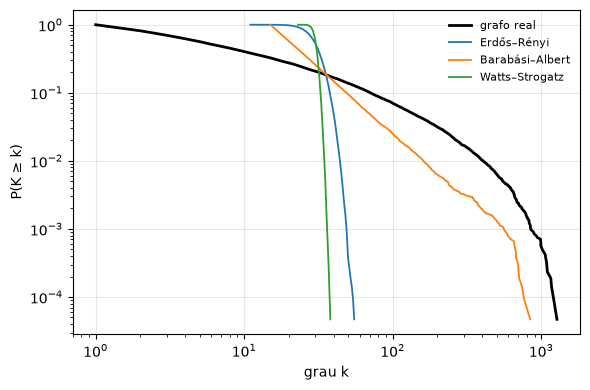

In [3]:
def media(nome, campo):
    return statistics.fmean(r[campo] for r in medidas[nome])

with open(DIR_RESULTADOS / "parte3_nulo_bipartido.csv", encoding="utf-8") as fluxo:
    nulo = next(csv.DictReader(fluxo))

cabecalho = ["grafo", "m", "C", "L", "k_max", "grau 1 (%)", "γ (MLE)", "k_min", "KS"]
linhas = []
for nome in medidas:
    linhas.append([nome, round(media(nome, "m")), f"{media(nome, 'C'):.4f}", f"{media(nome, 'L'):.3f}",
                   round(media(nome, "k_max")), f"{media(nome, 'grau 1 (%)'):.1f}", f"{media(nome, 'gama'):.2f}",
                   round(media(nome, "k_min")), f"{media(nome, 'KS'):.3f}"])
linhas.append([f"nulo bipartido ({nulo['replicas']} réplicas, n = {nulo['n']})", nulo["m"],
               f"{float(nulo['C']):.4f}", f"{float(nulo['L']):.3f}", "–", "–", "–", "–", "–"])
display(Markdown(formatar_markdown(cabecalho, linhas)))
with open(DIR_RESULTADOS / "parte3_modelos.csv", "w", encoding="utf-8") as fluxo:
    escrever_tabela(cabecalho, linhas, fluxo)
salvar_figura(plotar_ccdf_modelos(ccdfs), DIR_IMAGENS / "parte3_modelos_ccdf")

## Resposta Q5: nenhum modelo clássico descreve o grafo sozinho

- **Erdős–Rényi:** descartado. A clusterização é 230 vezes menor (0,0014 contra 0,32), o grau máximo é 55 contra 1.274, e não há cauda: o γ "ajustado" de 21 só diz que a distribuição cai abruptamente, como uma Poisson.
- **Watts–Strogatz** ($k = 30$, $p = 0{,}1$): reproduz o agrupamento, até com sobra ($C = 0{,}53$), mas os graus são quase iguais (máximo 38) e os caminhos ficam mais longos que no grafo real (4,09 contra 3,78). Não tem hubs.
- **Barabási–Albert** ($m_0 = 15$): é o mais próximo na distribuição de graus. Gera hubs (grau máximo 863) e uma lei de potência quase perfeita (γ = 2,93, perto do 3 teórico, KS = 0,004), com o caminho médio mais curto (2,99). Mas erra em três pontos: $C$ é 38 vezes menor (0,0085), não há vértices de grau 1 (o grau mínimo é $m_0$), contra 18,6% no grafo real, e a cauda real é mais pesada (γ = 2,11) e, segundo a Q2, mais próxima de uma lognormal.
- **Nulo bipartido:** é o único que reproduz a clusterização (0,36 contra 0,32), porque usa o mesmo mecanismo do grafo real: cada usuário vira um clique na projeção.

**Conclusão.** O grafo combina a cauda pesada do BA com o agrupamento do WS, mas o agrupamento não vem de religação de um anel: vem da projeção de um bipartido com graus heterogêneos. O modelo gerador adequado é um bipartido aleatório com os graus de usuários e produtos, projetado (Newman, Strogatz e Watts, 2001), e não um dos três clássicos de grafo simples. O caminho médio real, mais longo que o desse nulo, mostra o que resta de estrutura: a segregação por família de console (Q4).